<a href="https://colab.research.google.com/github/sakshi3121826/Basic-project-data-analysis/blob/main/project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/fitness_tracker.csv")
df.head()

,date,steps,active_minutes,calories_burned,sleep_hours,weight_kg,workout_type
0,2025-01-01,4735.0,32.0,1970.0,8.9,75.3,Walk
1,2025-01-02,9020.0,65.0,2254.0,8.7,75.3,Run
2,2025-01-03,8346.0,53.0,2047.0,7.7,75.1,Gym
3,2025-01-04,9458.0,64.0,2013.0,7.9,75.2,Walk
4,2025-01-05,13088.0,85.0,2382.0,8.4,75.3,Walk


In [3]:
# find the missing value
df.isna().sum()

,0
date,0
steps,15
active_minutes,0
calories_burned,0
sleep_hours,0
weight_kg,0
workout_type,0


In [4]:
# task1
df['date']=pd.to_datetime(df['date'])
df['steps']=df['steps'].fillna(df['steps'].median())

In [5]:
df.isna().sum()

,0
date,0
steps,0
active_minutes,0
calories_burned,0
sleep_hours,0
weight_kg,0
workout_type,0


In [8]:
# task  2 add 7-day rolling average of steps  and weight
df['step_7d']=df['steps'].rolling(7).mean()
df['weight_7d']=df['weight_kg'].rolling(7).mean()
df[['steps','step_7d','weight_kg','weight_7d']].head(10)


,steps,step_7d,weight_kg,weight_7d
0,4735.0,NaN,75.3,NaN
1,9020.0,NaN,75.3,NaN
2,8346.0,NaN,75.1,NaN
3,9458.0,NaN,75.2,NaN
4,13088.0,NaN,75.3,NaN
5,3869.0,NaN,74.9,NaN
6,9014.0,8218.571429,74.6,75.100000
7,8386.0,8740.142857,75.5,75.128571
8,6312.0,8353.285714,75.1,75.100000
9,12572.0,8957.000000,74.8,75.057143


In [9]:
df=df.sort_values('date').reset_index(drop=True)
print(df)

          date    steps  active_minutes  calories_burned  sleep_hours  \
0   2025-01-01   4735.0            32.0           1970.0          8.9   
1   2025-01-02   9020.0            65.0           2254.0          8.7   
2   2025-01-03   8346.0            53.0           2047.0          7.7   
3   2025-01-04   9458.0            64.0           2013.0          7.9   
4   2025-01-05  13088.0            85.0           2382.0          8.4   
..         ...      ...             ...              ...          ...   
360 2025-12-27   9042.0            59.0           2292.0          8.8   
361 2025-12-28  10605.0            62.0           2166.0          8.0   
362 2025-12-29   9624.0            57.0           2124.0          7.0   
363 2025-12-30   7958.0            47.0           2205.0          7.6   
364 2025-12-31   6278.0            40.0           2059.0          8.2   

     weight_kg workout_type     steps_7d  weight_7d      step_7d  
0         75.3         Walk          NaN        NaN     

In [11]:
# task 3 compare weekdays and weekends with a group
df['day_type']=np.where(df['date'].dt.dayofweek>=5,'weekend','weekday')
print(df)

          date    steps  active_minutes  calories_burned  sleep_hours  \
0   2025-01-01   4735.0            32.0           1970.0          8.9   
1   2025-01-02   9020.0            65.0           2254.0          8.7   
2   2025-01-03   8346.0            53.0           2047.0          7.7   
3   2025-01-04   9458.0            64.0           2013.0          7.9   
4   2025-01-05  13088.0            85.0           2382.0          8.4   
..         ...      ...             ...              ...          ...   
360 2025-12-27   9042.0            59.0           2292.0          8.8   
361 2025-12-28  10605.0            62.0           2166.0          8.0   
362 2025-12-29   9624.0            57.0           2124.0          7.0   
363 2025-12-30   7958.0            47.0           2205.0          7.6   
364 2025-12-31   6278.0            40.0           2059.0          8.2   

     weight_kg workout_type     steps_7d  weight_7d      step_7d day_type  
0         75.3         Walk          NaN       

In [12]:
df.groupby('day_type')[['steps','active_minutes','calories_burned','sleep_hours']].mean().round(1)

,steps,active_minutes,calories_burned,sleep_hours
day_type,,,,
weekday,7875.7,52.5,2118.0,7.0
weekend,9693.4,65.9,2188.8,7.6


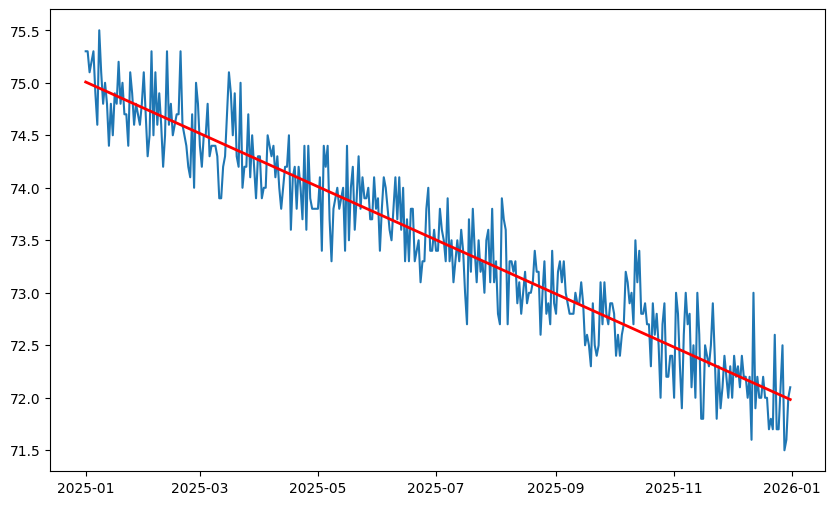

In [14]:
# 4 plot weight over time and mark the trend line
x=np.arange(len(df))
slope,intercept=np.polyfit(x,df['weight_kg'],1)
plt.figure(figsize=(10,6))
plt.plot(df['date'],df['weight_kg'],label='Daily weight')
plt.plot(df['date'],slope*x+intercept,color='red',linewidth=2)


In [15]:
df

,date,steps,active_minutes,calories_burned,sleep_hours,weight_kg,workout_type,steps_7d,weight_7d,step_7d,day_type
0,2025-01-01,4735.0,32.0,1970.0,8.9,75.3,Walk,NaN,NaN,NaN,weekday
1,2025-01-02,9020.0,65.0,2254.0,8.7,75.3,Run,NaN,NaN,NaN,weekday
2,2025-01-03,8346.0,53.0,2047.0,7.7,75.1,Gym,NaN,NaN,NaN,weekday
3,2025-01-04,9458.0,64.0,2013.0,7.9,75.2,Walk,NaN,NaN,NaN,weekend
4,2025-01-05,13088.0,85.0,2382.0,8.4,75.3,Walk,NaN,NaN,NaN,weekend
...,...,...,...,...,...,...,...,...,...,...,...
360,2025-12-27,9042.0,59.0,2292.0,8.8,72.5,Run,5438.000000,72.014286,5438.000000,weekend
361,2025-12-28,10605.0,62.0,2166.0,8.0,71.5,Walk,6048.428571,71.971429,6048.428571,weekend
362,2025-12-29,9624.0,57.0,2124.0,7.0,71.6,Gym,6559.571429,71.957143,6559.571429,weekday
363,2025-12-30,7958.0,47.0,2205.0,7.6,72.0,Rest,7079.142857,71.871429,7079.142857,weekday


<Axes: xlabel='workout_type', ylabel='calories_burned'>

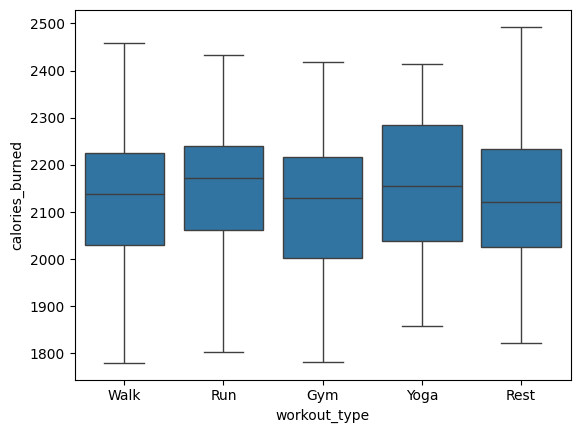

In [18]:
# # Make a correlation heatmap and a box plot of calories by workout type
cols=['weight_kg','steps','active_minutes','calories_burned','sleep_hours']
# sns.heatmap
#(df[cols].corr(),annot=True)
sns.boxplot(data=df,x='workout_type',y='calories_burned')


In [19]:
# 6 Write a conclusion on whether the user hit a 10,000 steps goal
goal_days=(df['steps']>=10000).sum()
goal_days
print(f"Goal met on {goal_days} of {len(df)} days ({goal_days/len(df)*100:.1f}%)")
print("Average steps:",round(df['steps'].mean()))

Goal met on 100 of 365 days (27.4%)
Average steps: 8394
